### Singular Isothermal Sphere

In [40]:
from gwlens.lens import sis
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from astropy import units as u
plotting.apply_figure_style()


#Let us initiate the class 
sis  = sis.SIS()



#### Make use of python help

Python help function is a great way to understand  different methods inside the SIS lens class.

In [3]:
help(sis)

Help on SIS in module gwlens.lens.sis object:

class SIS(gwlens.lens.base.Lens)
 |  SIS(**params)
 |  
 |  Method resolution order:
 |      SIS
 |      gwlens.lens.base.Lens
 |      abc.ABC
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  Amplification(self, w, y, type='both')
 |      Computes geometric optics amplification factor for Point Mass Lens
 |      
 |      Parameters:
 |      
 |      w: Dimensionless frequency
 |      y: Impact parameter
 |      
 |      type: Nature of the image: minimum, saddle, both
 |  
 |  Dimensionless_Frequency(self, f, sigma, Dl, Ds)
 |  
 |  Effective_Lens_Mass(self, sigma, zL, zS)
 |  
 |  Fermat_Potential(self, x1, x2, y1, y2)
 |  
 |  Hessian(self, x1, x2)
 |  
 |  Image_count(self, y1, y2, method='analytic')
 |      Total image count is not fixed ( 2 images maximum) for SIS lens model.
 |      But it can also be calculated directly from the method
 |      solve_images. The number of independent solutions correspond to number of i

## Calculating lensing properties

In [54]:
### We already initialized the SIS class

y1 = 0.905
y2 = 0  #Set this to zero because SIS modelled is axially symmetric


# To find the position of images for a give impact parameter
sol = sis.solve_images(y1,y2, method="analytic")

#Its returns a  dictionary of various useful quantities

for img in sol:
    print("Image:",img["type"])
    print("Position:", img["position"])
    print("Magnification",img["magnification"])
    print("Morse Factor",img["Morse"])
    print('******')




#Calculate time-delay
sigma_v = 200 #In units of km/s
timedelay = sis.Time_Delay(y1,y2,sigma_v,zL=1.0,zS=2.0)


#The output is an astropy quantity and consists of arrival time of both the images,
#The first quantity is the arrival time of the first image and which is always normalized to 0
#The second quantity is the arrival time of the second image

print("TimeDelay",timedelay)

#One can use astropy to convert it into days as follows
print("Time after which the second image arrives:", timedelay[1].to(u.day))

Image: minimum
Position: (1.905, 0.0)
Magnification 2.1049723756906076
Morse Factor 0
******
Image: saddle
Position: (-0.09499999999999997, -0.0)
Magnification -0.10497237569060773
Morse Factor 1
******
TimeDelay [<Quantity 0. s>, <Quantity 6933156.23366872 s>]
Time after which the second image arrives: 80.2448638156102 d


### Amplification factor

Below we see an example for plotting the SIS amplification factor in Geometric Optics limit. 
For Wave Optics limit, see the getting started tutorial.

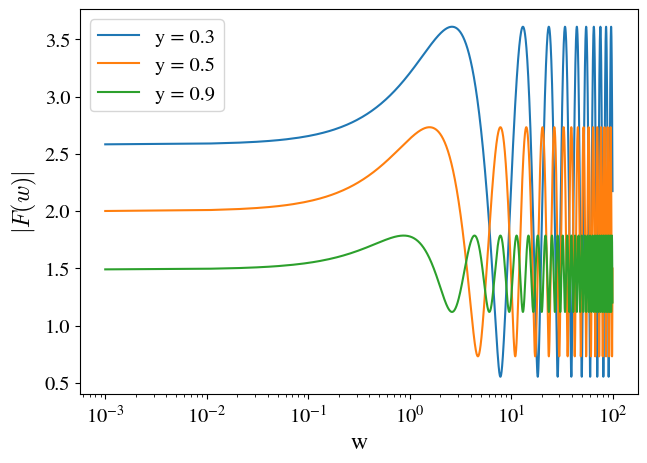

In [63]:
w = np.linspace(0.001,100,10000)
y_val = [0.3,0.5,0.9]
c = ["red","black", "olive"]

for i in range(len(y_val)):

    F = sis.Amplification(w,y_val[i])
    plt.plot(w, np.abs(F), label=f"y = {y_val[i]}")
plt.xlabel("w")
plt.ylabel("$|F(w)|$")
plt.xscale("log")
plt.legend()

### Sampling SIS magnification and time-delay


The image magnification and the corresponding time-delay fucntion can be sampled from sample method inside the SIS lens class


In [4]:
help(sis.sample)

Help on method sample in module gwlens.lens.sis:

sample(N=10000, y_max=2.0, y_min=0.001, sigma_v_range=(150, 300), zL=0.5, zS=2.0, seed=None) method of gwlens.lens.sis.SIS instance
    Sample SIS lensing observables.
    
    Returns:
        dict with:
            y              : impact parameter
            mu1, mu2       : magnifications
            x1, x2         : image positions
            delta_t        : time delay (arbitrary units)
            sigma_v        : velocity dispersion



In [6]:
#To sample an SIS lens 
# Choose how many samples you want to generate
N  =  100000  #default value is 1e+4  
y_max = 1.0 # default value is 2.0 

# Rmemeber after y >1, the number of images reduce to 1.0

y_min = 0.001 

#Choose the velocity dispersion range of your galaxies
sigma_v_range = 180,300

# Choose lens and source redshift, it is important for accurate time-delay calculation

zL = 0.5
zS = 1.8

# Now you are ready to sample
samples = sis.sample(N,y_max,y_min,sigma_v_range,zL,zS)

In [27]:
y = samples["y"]
sigma = samples["sigma_v"]
mu1 = samples["mu1"]
mu2 = samples["mu2_abs"]
td = samples["delta_t"]

##### $P(\mu)$ of sampled images

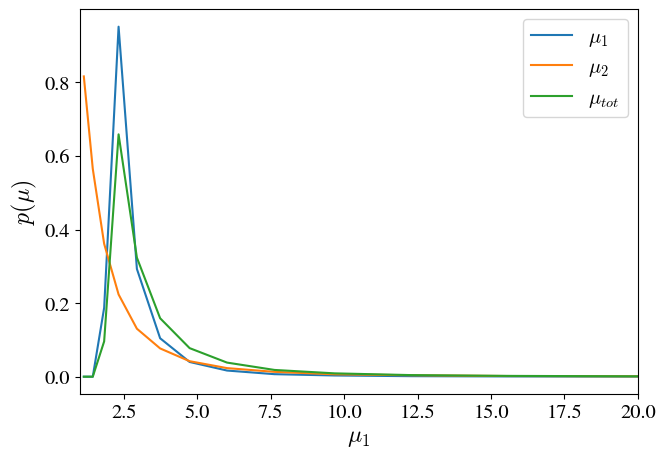

In [41]:
bins = np.logspace(0, 3, 30)
hist_mu1, edges = np.histogram(mu1, bins=bins, density=True)
centers_mu1 = 0.5 * (edges[:-1] + edges[1:])
plt.plot(centers_mu1, hist_mu1, label="$\\mu_{1}$")


hist_mu2, edges2 = np.histogram(mu2, bins=bins, density=True)
centers_mu2 = 0.5 * (edges2[:-1] + edges2[1:])
plt.plot(centers_mu2, hist_mu2, label="$\\mu_{2}$")


mu_tot = mu1+mu2
hist_mu_tot, edges3 = np.histogram(mu_tot, bins=bins, density=True)
centers_mu3 = 0.5 * (edges3[:-1] + edges3[1:])
plt.plot(centers_mu3, hist_mu_tot, label="$\\mu_{tot}$")

plt.legend()
plt.xlim(1.0,20)
plt.ylabel(r"$p(\mu)$")
plt.xlabel("$\mu_{1}$")
plt.show()
